# Tarea 2 · Parte 2 — De los modelos base a la extracción estructurada

Plan del notebook:

1. **Muestra de evaluación** sin datos nuevos: 10 documentos (4 impresos, 3 fotos, 3 manuscritos) y
   10 clips (5 lecturas de OpenSLR 73, la entrevista simulada multihablante y 4 entrevistas reales de
   Commons) **tomados del corpus de la Parte 1**, con transcripción de referencia manual.
2. **Línea base**: PaddleOCR por defecto (CER) y faster-whisper small en CPU (WER).
3. **Modelos alternativos** sobre exactamente los mismos 20 archivos: PaddleOCR con preprocesamiento,
   EasyOCR y Tesseract; faster-whisper large-v3-turbo y Qwen3-ASR 0.6B (WER y factor de tiempo real).
4. **Casos difíciles**: manuscritos, fotos, ruido de calle y varias voces.
5. **Extracción estructurada con un LLM** (Gemini) y **auditoría humana** de 20 extracciones.
6. **Tabla comparativa y decisión.**

**Cómo se ejecuta (dos pasadas).** En la primera, el notebook elige la muestra, crea las plantillas
de referencia, corre todos los modelos y el LLM y **guarda sus salidas** en `datos/raw/hipotesis/`
sin mirar ninguna referencia. Se detiene pidiendo las referencias manuales y la auditoría. En la
segunda pasada solo lee lo guardado y calcula CER/WER, tablas y gráficos.

**Regla anti-sobreajuste.** Todas las configuraciones, la normalización y la regla de decisión están
fijadas en `modelos/config_evaluacion.json`, escrito **antes** de calcular cualquier métrica. Ningún
parámetro se cambia después de ver los resultados, y todos los modelos se evalúan sobre los mismos archivos.

In [1]:
import os, sys, json, gc, re, time, warnings, difflib
from pathlib import Path
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
warnings.filterwarnings("ignore")

RAIZ = Path.cwd()
assert (RAIZ / "src" / "t2.py").exists(), "Abre este notebook desde la carpeta tarea_2/"
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
import plotly.express as px
import t2, voz

DATOS, RAW = RAIZ / "datos", RAIZ / "datos" / "raw"
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

CFG = json.loads((RAIZ / "modelos" / "config_evaluacion.json").read_text(encoding="utf-8"))
docs = pd.read_csv(DATOS / "documentos.csv", dtype={"texto_referencia": str}, keep_default_na=False)
aud = pd.read_csv(DATOS / "transcripciones.csv", dtype={"texto_referencia": str}, keep_default_na=False)
print(f"Corpus de la Parte 1: {len(docs)} documentos · {len(aud)} clips ({aud['duracion_seg'].sum() / 60:.1f} min)")
print("Configuración fijada:", CFG["_nota"])

Corpus de la Parte 1: 25 documentos · 30 clips (38.0 min)
Configuración fijada: Configuraciones fijadas el 2026-10-25, ANTES de calcular cualquier métrica. No se modifican después de ver resultados.


## 1 · Muestra de evaluación (10 documentos + 10 clips del corpus original)

Criterios, fijados en la configuración:

- **Documentos:** muestreo aleatorio estratificado con semilla 2026 — 4 impresos, 3 fotos y
  3 manuscritos — entre los documentos cuyo OCR tiene ≤ 1500 caracteres (para que la transcripción
  manual sea factible; se usa solo el largo, nunca el error). Se incluye siempre la tarjeta de
  Ricardo Palma, cuya transcripción manual línea a línea viene de la Sesión 10 y se verifica contra la imagen.
- **Audio:** 5 sesiones de lectura de OpenSLR 73, la entrevista simulada de 2 hablantes y 4 clips de
  entrevistas reales de Commons, de fuentes distintas cuando es posible (calle, conferencia de prensa…).

La selección se guarda en `datos/muestra_evaluacion.json` la primera vez y después se reutiliza.

**Referencias manuales.** Se crean plantillas en `datos/raw/referencias/` (fuera de Git, porque una
transcripción manual de una entrevista puede tener nombres reales; lo publicado es la versión
seudonimizada en la columna `texto_referencia`):

- documentos y clips de Commons: **se transcriben a mano** mirando la imagen o escuchando el audio
  (no se copia la salida de ningún modelo);
- OpenSLR 73 y la entrevista simulada traen la **transcripción humana oficial del corpus** como
  borrador: se escucha cada clip y se corrige lo que no coincida.

Cada plantilla tiene una línea `# verificado: no`; las métricas **no se calculan** hasta que todas digan
`# verificado: si`. Mientras tanto se pueden correr los modelos, porque no usan las referencias.

In [2]:
ruta_muestra = DATOS / "muestra_evaluacion.json"
if ruta_muestra.exists():
    muestra = json.loads(ruta_muestra.read_text(encoding="utf-8"))
    print("Muestra cargada de", ruta_muestra.name, "(fijada el", muestra["fecha"] + ")")
else:
    rng = np.random.default_rng(CFG["semilla_muestra"])
    sel_docs = []
    for tipo, k in CFG["muestra_documentos"].items():
        pool = docs[docs["tipo"] == tipo]
        cortos = pool[pool["n_caracteres_ocr"] <= CFG["max_caracteres_ocr_para_muestra"]]
        pool = cortos if len(cortos) >= k else pool
        forzados = list(pool[pool["titulo"].str.contains("Ricardo Palma", na=False)]["id"])[:1]
        resto = [i for i in pool["id"] if i not in forzados]
        sel_docs += forzados + list(rng.choice(resto, size=k - len(forzados), replace=False))
    sel_aud = []
    lect = aud[aud["condicion"] == "lectura (OpenSLR 73)"]["id"]
    sel_aud += list(rng.choice(lect, size=CFG["muestra_audio"]["lectura (OpenSLR 73)"], replace=False))
    sel_aud += list(aud[aud["condicion"] == "multihablante (simulada)"]["id"])[:1]
    com = aud[aud["condicion"] == "entrevista real (Commons)"].copy()
    com["azar"] = rng.random(len(com))
    com = com.sort_values("azar")
    k = CFG["muestra_audio"]["entrevista real (Commons)"]
    uno_por_fuente = list(com.drop_duplicates("id_fuente")["id"])[:k]
    sel_aud += uno_por_fuente + [i for i in com["id"] if i not in uno_por_fuente][:k - len(uno_por_fuente)]
    muestra = {"fecha": time.strftime("%Y-%m-%d %H:%M"), "documentos": sorted(map(str, sel_docs)),
               "audio": sorted(map(str, sel_aud)), "criterio": "ver config_evaluacion.json"}
    ruta_muestra.write_text(json.dumps(muestra, ensure_ascii=False, indent=1), encoding="utf-8")

M_DOC, M_AUD = muestra["documentos"], muestra["audio"]
display(docs[docs["id"].isin(M_DOC)][["id", "tipo", "titulo", "n_caracteres_ocr"]])
display(aud[aud["id"].isin(M_AUD)][["id", "condicion", "id_fuente", "duracion_seg", "n_hablantes"]])
print(f"Muestra: {len(M_DOC)} documentos y {len(M_AUD)} clips ({aud[aud['id'].isin(M_AUD)]['duracion_seg'].sum() / 60:.1f} min)")

Muestra cargada de muestra_evaluacion.json (fijada el 2026-10-25 14:21)


,id,tipo,titulo,n_caracteres_ocr
2,doc_003,impreso,10 Intis 1987(front).jpg,128
4,doc_005,impreso,1000 Intis 1988(Front).jpg,124
5,doc_006,impreso,10000 Intis 1988(Front).jpg,130
6,doc_007,impreso,500000 Intis 1988(Front).jpg,159
9,doc_012,foto,Carteles chicha.jpg,811
11,doc_014,manuscrito,Tarjeta de Ricardo Palma a Luis Antonio Eguiguren Escudero 24 octubre 1912.png,389
14,doc_017,foto,Placa conmemorativa del Teatro Colón en Lima.jpg,200
15,doc_019,foto,Pasaje Acisclo Villarán - Placa conmemorativa.jpg,165
21,doc_026,manuscrito,Asiento de la partida de bautismo de Raúl Porras Barrenechea.jpg,556
24,doc_031,manuscrito,Libro de Bautismos en la Gran Villa de Lampa 1871.jpg,227


,id,condicion,id_fuente,duracion_seg,n_hablantes
7,clip_008,entrevista real (Commons),commons_03,92.2,3
9,clip_010,entrevista real (Commons),commons_06,98.3,2
11,clip_012,entrevista real (Commons),commons_08,54.3,11
14,clip_015,entrevista real (Commons),commons_09,80.0,2
18,clip_019,lectura (OpenSLR 73),openslr73_pef_01523,70.6,1
19,clip_020,lectura (OpenSLR 73),openslr73_pem_00610,74.3,1
21,clip_022,lectura (OpenSLR 73),openslr73_pem_05223,55.6,1
23,clip_024,lectura (OpenSLR 73),openslr73_pem_07508,102.3,1
24,clip_025,lectura (OpenSLR 73),openslr73_pef_07508,75.4,1
29,clip_030,multihablante (simulada),entrevista_simulada,98.0,2


Muestra: 10 documentos y 10 clips (13.3 min)


In [3]:
REF = RAW / "referencias"
(REF / "documentos").mkdir(parents=True, exist_ok=True)
(REF / "audio").mkdir(parents=True, exist_ok=True)

# Transcripción manual de la tarjeta de Ricardo Palma hecha en la Sesión 10 (clase de PaddleOCR),
# línea por línea, tal como está escrita: arriba el manuscrito, abajo su versión impresa.
PALMA = '''Agradezco muy sinceramente
la fina atención de mi joven a-
migo Luis Antonio Eguiguren al
obsequiarme los dos folletos cuya lec-
tura haré próximamente, y le estimaré
infinito que, cuando le sea posible, favo-
rezca con su ofrecida visita á este
su valetudinario amigo
Ricardo Palma
Miraflores, 24 de Octubre de 1912.
"Agradezco muy sinceramente la fina atención de mi joven amigo
Luis Antonio Eguiguren al obsequiarme dos folleti tos cuya lectura
haré próximamente, y le estimaré infinito que, cuando sea posible,
favorezca con su ofrecida visita a éste su valetudinario amigo"
Ricardo Palma
Miraflores, 24 de Octubre de 1912.'''

inv_audio = pd.read_csv(RAW / "audio" / "inventario.csv", keep_default_na=False).set_index("id_fuente")
for r in docs[docs["id"].isin(M_DOC)].itertuples():
    p = REF / "documentos" / f"{r.id}.txt"
    if p.exists():
        continue
    cab = (f"# Documento {r.id} ({r.tipo}): {r.titulo}\n# Imagen: {r.archivo}\n"
           "# Transcribe A MANO todo el texto visible, en orden de lectura y con la ortografía original.\n"
           "# No copies la salida del OCR. Las líneas que empiezan con # se ignoran.\n")
    cuerpo = ""
    if "Ricardo Palma" in r.titulo:
        cab += "# Borrador: transcripción manual de la Sesión 10. Compárala con la imagen y agrega el texto que falte.\n"
        cuerpo = PALMA
    p.write_text(cab + "# verificado: no\n" + cuerpo + "\n", encoding="utf-8")

for r in aud[aud["id"].isin(M_AUD)].itertuples():
    p = REF / "audio" / f"{r.id}.txt"
    if p.exists():
        continue
    cab = f"# Clip {r.id} ({r.condicion}) · audio: {r.archivo_audio} · {r.duracion_seg:.0f} s\n"
    oficial = inv_audio.at[r.id_fuente, "referencia_oficial"] if r.id_fuente in inv_audio.index else ""
    if oficial:
        cab += ("# Borrador: transcripción humana oficial de OpenSLR 73. ESCUCHA el clip completo y corrige lo que no coincida.\n")
    else:
        cab += ("# Escucha el clip y transcribe A MANO todo lo que se dice (sin marcas de hablante). No copies la salida del ASR.\n"
                "# Si alguien dice su nombre, escribe [PERSONA].\n")
    p.write_text(cab + "# Las líneas que empiezan con # se ignoran.\n# verificado: no\n" + (oficial or "") + "\n", encoding="utf-8")

def leer_ref(p):
    lineas = p.read_text(encoding="utf-8-sig").splitlines()
    verificado = any(re.match(r"#\s*verificado:\s*s[ií]\b", l, re.I) for l in lineas)
    texto = "\n".join(l for l in lineas if not l.lstrip().startswith("#")).strip()
    return texto, verificado

pendientes = []
dicc = t2.cargar_seudonimos()
for df, carpeta, ids, modo in [(docs, "documentos", M_DOC, "documento"), (aud, "audio", M_AUD, "audio")]:
    for i in ids:
        texto, ok = leer_ref(REF / carpeta / f"{i}.txt")
        if not texto or not ok:
            pendientes.append(f"datos/raw/referencias/{carpeta}/{i}.txt" + ("" if texto else " (vacía)"))
        df.loc[df["id"] == i, "texto_referencia"] = t2.seudonimizar_texto(texto, dicc, modo=modo)[0]

REFS_OK = not pendientes
if REFS_OK:
    docs.to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
    aud.to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")
    print("✅ 20 referencias manuales cargadas (seudonimizadas) en la columna texto_referencia de ambos CSV")
else:
    print(f"Faltan {len(pendientes)} referencias manuales verificadas. El notebook sigue corriendo los modelos "
          "(no usan las referencias) y se detendrá antes de calcular métricas:\n  " + "\n  ".join(pendientes))

✅ 20 referencias manuales cargadas (seudonimizadas) en la columna texto_referencia de ambos CSV


## 2 · Línea base sin ajuste

- **OCR:** PaddleOCR 3.7 por defecto, sin orientación ni *unwarping* (la configuración del corpus).
- **ASR:** faster-whisper **small** en CPU (int8, beam 5, VAD activado, `language="es"`).

Se vuelven a ejecutar sobre la muestra para medir también el tiempo. La primera pasada de cada
modelo («calentamiento») no se cronometra.

In [4]:
DIR_PROC = RAW / "documentos" / "procesadas"
eval_docs = docs[docs["id"].isin(M_DOC)].copy()
eval_docs["imagen"] = [t2.preparar_imagen(RAIZ / a, DIR_PROC) for a in eval_docs["archivo"]]

HIP = RAW / "hipotesis"
HIP.mkdir(parents=True, exist_ok=True)

def evaluar_ocr(nombre, crear, leer, rol):
    "Corre un OCR sobre los 10 documentos y guarda texto y tiempo. No usa las referencias."
    cache = HIP / f"ocr_{nombre}.csv"
    if cache.exists():
        res = pd.read_csv(cache, keep_default_na=False)
        print(f"{nombre:<20} (salidas guardadas) {res['segundos'].mean():.1f} s por página")
        return res
    modelo, descripcion = crear()
    leer(modelo, eval_docs["imagen"].iloc[0])             # calentamiento
    filas = []
    for r in eval_docs.itertuples():
        t0 = time.perf_counter()
        hip = leer(modelo, r.imagen)
        seg = time.perf_counter() - t0
        filas.append({"id": r.id, "tipo": r.tipo, "modelo": nombre, "rol": rol, "descripcion": descripcion,
                      "segundos": seg, "texto_hipotesis": hip})
    res = pd.DataFrame(filas)
    res.to_csv(cache, index=False, encoding="utf-8")
    print(f"{nombre:<20} {res['segundos'].mean():.1f} s por página")
    del modelo
    gc.collect()
    return res

leer_pp = lambda m, p: t2.texto_de_lineas(t2.leer_paddle(m, p))
res_ocr = [evaluar_ocr("paddleocr-base", lambda: t2.crear_paddle(t2.OPCIONES_BASE), leer_pp, "base")]

paddleocr-base       (salidas guardadas) 39.8 s por página


In [5]:
eval_aud = aud[aud["id"].isin(M_AUD)].copy()
audios_eval = {r.id: voz.cargar_audio(RAIZ / r.archivo_audio) for r in eval_aud.itertuples()}

def evaluar_asr(clave, rol):
    "Corre un ASR sobre los 10 clips y guarda texto, tiempo y RTF. No usa las referencias."
    cache = HIP / f"asr_{clave}.csv"
    if cache.exists():
        res = pd.read_csv(cache, keep_default_na=False)
        print(f"{clave:<22} (salidas guardadas) RTF {res['segundos'].sum() / res['duracion_seg'].sum():.2f}")
        return res
    t = voz.Transcriptor(clave)
    t.transcribir(np.zeros(voz.SR * 2, dtype=np.float32) + 1e-4, "es")   # calentamiento
    filas = []
    for r in eval_aud.itertuples():
        x = audios_eval[r.id]
        t0 = time.perf_counter()
        segs = t.segmentos(x, idioma="es")
        seg = time.perf_counter() - t0
        hip = " ".join(s.texto for s in segs)
        filas.append({"id": r.id, "condicion": r.condicion, "modelo": clave, "rol": rol, "descripcion": t.info["nombre"],
                      "segundos": seg, "duracion_seg": len(x) / voz.SR,
                      "rtf": seg / (len(x) / voz.SR), "texto_hipotesis": hip,
                      "alucinaciones": "; ".join(t2.posibles_alucinaciones(hip))})
    res = pd.DataFrame(filas)
    res.to_csv(cache, index=False, encoding="utf-8")
    print(f"{clave:<22} RTF {res['segundos'].sum() / res['duracion_seg'].sum():.2f} · carga {t.segundos_carga:.0f} s")
    del t
    gc.collect()
    return res

res_asr = [evaluar_asr(CFG["asr"]["base"]["modelo"], "base")]

faster-whisper-small   (salidas guardadas) RTF 0.11


## 3 · Modelos alternativos (mismos 10 documentos y 10 clips)

**OCR**

- *PaddleOCR mejorado*: el mismo PP-OCRv6 con clasificación de orientación de página, *unwarping*
  (enderezar hojas curvas o fotografiadas en ángulo) y orientación por línea. Ataca justamente las
  fotos inclinadas y con sombras.
- *EasyOCR*: arquitectura distinta (detector CRAFT + reconocedor CRNN), se instala con `pip` en
  Windows sin binarios del sistema; sirve como segunda opinión independiente de Paddle.
- *Tesseract 5* (LSTM, `spa`): el OCR clásico de referencia. Solo corre si está instalado.

**ASR**

- *faster-whisper large-v3-turbo*: la misma familia que la base pero 3× más parámetros.
- *Qwen3-ASR 0.6B* (Alibaba, Apache 2.0): otra arquitectura (LLM de audio), mismo tamaño que small;
  se le pasa cada tramo del VAD. Si no carga en el equipo, se usa Parakeet TDT 0.6B v3 como respaldo.

In [6]:
res_ocr.append(evaluar_ocr("paddleocr-mejorado", lambda: t2.crear_paddle(t2.OPCIONES_MEJORADO), leer_pp, "alternativo"))

try:
    import easyocr  # noqa: F401
    res_ocr.append(evaluar_ocr("easyocr", t2.crear_easyocr, t2.leer_easyocr, "alternativo"))
except ImportError:
    print("EasyOCR no está instalado (uv pip install easyocr): se omite")

if t2.tesseract_disponible():
    import pytesseract
    res_ocr.append(evaluar_ocr("tesseract", lambda: (None, f"Tesseract {pytesseract.get_tesseract_version()} (LSTM, spa, psm 3)"),
                               lambda m, p: t2.leer_tesseract(p), "alternativo"))
else:
    print("Tesseract no está instalado con el idioma 'spa': se omite (ver README)")

paddleocr-mejorado   (salidas guardadas) 32.4 s por página


easyocr              (salidas guardadas) 6.5 s por página
Tesseract no está instalado con el idioma 'spa': se omite (ver README)


In [7]:
for alt in CFG["asr"]["alternativos"]:
    try:
        res_asr.append(evaluar_asr(alt["modelo"], "alternativo"))
    except Exception as e:
        print(f"{alt['modelo']} falló: {type(e).__name__}: {str(e)[:150]}")
        if alt.get("respaldo"):
            print(f"  → uso el respaldo definido de antemano: {alt['respaldo']}")
            res_asr.append(evaluar_asr(alt["respaldo"], "alternativo"))

faster-whisper         (salidas guardadas) RTF 0.19
qwen3-asr-0.6b         (salidas guardadas) RTF 0.31


## 4 · Extracción estructurada con un LLM (Gemini)

- **Entrada:** solo textos **ya seudonimizados** (`texto_ocr` y `texto_asr` de la Parte 1): ningún
  dato personal sale hacia la API.
- **Prompt estructurado** (`t2.INSTRUCCIONES`): esquema JSON fijo por modalidad; campos ausentes en
  `null`; prohibido usar conocimiento externo; citas clave copiadas literalmente.
- **Documentos:** `modalidad, tipo_documento, tema, resumen, emisor, fecha, monto, lugar, legible`.
- **Audio:** `modalidad, tema, resumen, numero_hablantes, citas_clave, lugar`.
- `temperature=0` y respuesta forzada a JSON (`response_mime_type="application/json"`).
  Las respuestas se guardan en caché (`datos/raw/llm_cache.jsonl`) para no repetir llamadas.

La clave va en `tarea_2/.env` (`GEMINI_API_KEY=...`), que está en `.gitignore`.

In [8]:
print("Prompt (documento):\n", t2.INSTRUCCIONES.format(esquema=t2.ESQUEMAS["documento"])[:900], "...")
ext = t2.ExtractorGemini()
print("Modelo:", ext.modelo)

filas_llm = []
for r in docs.itertuples():
    d = ext.extraer(r.id, "documento", r.texto_ocr)
    filas_llm.append({"id": r.id, "modalidad": "documento", "campos_json": json.dumps(d["campos"], ensure_ascii=False),
                      "modelo_llm": d["modelo_llm"], "fecha": d["fecha"]})
for r in aud.itertuples():
    d = ext.extraer(r.id, "audio", r.texto_asr)
    filas_llm.append({"id": r.id, "modalidad": "audio", "campos_json": json.dumps(d["campos"], ensure_ascii=False),
                      "modelo_llm": d["modelo_llm"], "fecha": d["fecha"]})
llm = pd.DataFrame(filas_llm)
llm.to_csv(DATOS / "extraccion_llm.csv", index=False, encoding="utf-8")
print(f"datos/extraccion_llm.csv: {llm.shape}")
llm.head()

Prompt (documento):
 Eres un asistente de archivística. Recibes texto obtenido automáticamente (OCR de un
documento peruano o transcripción automática de un audio en español peruano). Devuelve SOLO un
objeto JSON con exactamente estas claves y ninguna otra:

{"modalidad": "documento", "tipo_documento": str|null, "tema": str, "resumen": str, "emisor": str|null, "fecha": str|null, "monto": str|null, "lugar": str|null, "legible": bool}

Reglas obligatorias:
1. Usa únicamente información que aparezca en el texto. No completes con conocimiento externo.
2. Si un dato no aparece de forma explícita, usa null. Nunca inventes emisores, fechas ni montos.
3. "tema": 2 a 6 palabras. "resumen": una o dos oraciones en español, fieles al texto.
4. Fechas tal como aparecen (no conviertas formatos). Montos con su moneda si aparece (p. ej. "500 000 intis").
5. En audio, "citas_clave" es una lista de 1 a 3 frases copiadas liter ...


Modelos flash disponibles en tu cuenta: gemini-3.8-flash, gemini-3.7-flash, gemini-3.6-flash, gemini-3.5-flash, gemini-3.5-flash-lite, gemini-3.1-flash-lite, gemini-3.1-flash-lite-preview, gemini-3-flash-preview


  modelo gemini-3.8-flash no disponible: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quot


  modelo gemini-3.7-flash no disponible: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quot


  modelo gemini-3.6-flash no disponible: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quot


  modelo gemini-3.5-flash no disponible: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quot


Modelo: gemini-3.5-flash-lite
datos/extraccion_llm.csv: (55, 5)


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""Resolución de Alcaldía"", ""tema"": ""Reconocimiento de símbolos...",gemini-3.8-flash,2026-10-25 14:54
1,doc_002,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""periódico"", ""tema"": ""Examen de las diversiones públicas"", ""r...",gemini-3.8-flash,2026-10-25 14:56
2,doc_003,documento,"{""modalidad"": ""documento"", ""tipo_documento"": ""billete"", ""tema"": ""Billete de diez intis"", ""resumen"": ""Bille...",gemini-3.8-flash,2026-10-25 15:00
3,doc_004,documento,"{""modalidad"": ""documento"", ""tipo_documento"": null, ""tema"": ""Cien intis del Banco Central"", ""resumen"": ""Reg...",gemini-3.8-flash,2026-10-25 15:04
4,doc_005,documento,"{""modalidad"": ""documento"", ""tipo_documento"": null, ""tema"": ""Billete de mil intis"", ""resumen"": ""Texto corre...",gemini-3.6-flash,2026-10-25 18:59


In [9]:
campos = pd.json_normalize(llm["campos_json"].map(json.loads))
campos["id"] = llm["id"]
nulos = (campos.drop(columns=["id", "modalidad"]).isna().groupby(llm["modalidad"]).mean() * 100).round(0)
print("% de extracciones con el campo en null (el LLM no lo encontró en el texto):")
display(nulos.T.dropna(how="all"))

textos = dict(zip(aud["id"], aud["texto_asr"]))
verif = [t2.citas_verificables(json.loads(c), textos[i]) for i, c in zip(llm["id"], llm["campos_json"]) if i in textos]
verif = [v for v in verif if v is not None]
print(f"Chequeo automático: en {sum(verif)}/{len(verif)} audios todas las citas clave aparecen literalmente en la transcripción")

% de extracciones con el campo en null (el LLM no lo encontró en el texto):


modalidad,audio,documento
tipo_documento,100.0,56.0
tema,0.0,0.0
resumen,0.0,0.0
emisor,100.0,24.0
fecha,100.0,20.0
monto,100.0,72.0
lugar,67.0,40.0
legible,100.0,0.0
numero_hablantes,37.0,100.0
citas_clave,0.0,100.0


Chequeo automático: en 28/30 audios todas las citas clave aparecen literalmente en la transcripción


## 5 · Auditoría humana de 20 extracciones

Se eligen al azar (semilla 7) **10 documentos y 10 audios**. Se genera
`datos/raw/auditoria_plantilla.xlsx` con el texto y el JSON de cada caso; la persona revisora
completa con 1 (sí) o 0 (no):

| Columna | Criterio de corrección |
|---|---|
| `ok_modalidad_tema_resumen` | modalidad correcta; tema y resumen fieles al texto, sin afirmaciones que no estén en él |
| `ok_campos_con_valor` | cada campo con valor (emisor, fecha, monto, lugar, número de hablantes, citas) está respaldado por el texto; las citas son literales |
| `ok_nulls` | ningún dato que aparece claramente en el texto quedó en `null`, y ningún `null` fue «rellenado» con un dato inventado |

Una extracción es **completamente correcta** solo si las tres columnas valen 1. En `error_observado`
se anota qué falló. La confianza autodeclarada del LLM no se usa.

In [10]:
rng = np.random.default_rng(CFG["semilla_auditoria"])
ids_aud = list(rng.choice(llm[llm["modalidad"] == "documento"]["id"], 10, replace=False)) + \
          list(rng.choice(llm[llm["modalidad"] == "audio"]["id"], 10, replace=False))
plantilla = RAW / "auditoria_plantilla.xlsx"
textos_todos = dict(zip(docs["id"], docs["texto_ocr"])) | dict(zip(aud["id"], aud["texto_asr"]))
if not plantilla.exists():
    t = llm.set_index("id").loc[ids_aud].reset_index()
    t["texto_fuente"] = t["id"].map(textos_todos).str.slice(0, 3000)
    t["campos_json"] = t["campos_json"].map(lambda c: json.dumps(json.loads(c), ensure_ascii=False, indent=1))
    for c in ["ok_modalidad_tema_resumen", "ok_campos_con_valor", "ok_nulls", "error_observado"]:
        t[c] = ""
    t[["id", "modalidad", "texto_fuente", "campos_json", "ok_modalidad_tema_resumen", "ok_campos_con_valor",
       "ok_nulls", "error_observado"]].to_excel(plantilla, index=False)
print(f"Plantilla de auditoría: {plantilla}")

Plantilla de auditoría: C:\Users\PC\github-classroom\qlab-intro-python\tarea_2\datos\raw\auditoria_plantilla.xlsx


### ⏸️ Fin de la primera pasada

Todo lo anterior (modelos y LLM) ya quedó guardado. Desde aquí se necesitan las **referencias manuales
verificadas** y la **auditoría humana**: si falta algo, la celda siguiente se detiene y dice qué completar.

In [11]:
aud_h = pd.read_excel(plantilla, dtype={"error_observado": str}).fillna({"error_observado": ""})
cols_ok = ["ok_modalidad_tema_resumen", "ok_campos_con_valor", "ok_nulls"]
falta_aud = bool(aud_h[cols_ok].isna().any().any())
if not REFS_OK or falta_aud:
    if not REFS_OK:
        print("1) Completa y marca '# verificado: si' en:\n  " + "\n  ".join(pendientes))
    if falta_aud:
        print(f"2) Completa la auditoría (1 = correcto, 0 = incorrecto) en {plantilla}")
    print("\nLuego: Kernel → Restart Kernel and Run All Cells (los modelos NO se vuelven a correr: están guardados).")
    raise RuntimeError("Faltan pasos humanos: referencias manuales y/o auditoría")
print("✅ Referencias y auditoría completas: se calculan las métricas")

✅ Referencias y auditoría completas: se calculan las métricas


## 6 · Métricas · normalización común

Referencias e hipótesis pasan por `t2.normalizar`: minúsculas, sin puntuación, sin marcas entre
corchetes (`[HABLANTE_1]`, `[PERSONA]`…, que no son palabras habladas), espacios simples. Se
**conservan** tildes y eñes: un OCR que pierde la tilde comete un error. CER y WER se reportan
**agregados** (ediciones totales / largo total de las referencias, como `jiwer`) y por archivo.

In [12]:
ej = aud[aud["id"].isin(M_AUD)].iloc[0]
print("Referencia :", ej.texto_referencia[:160])
print("Normalizada:", t2.normalizar(ej.texto_referencia)[:160])
print("ASR corpus :", t2.normalizar(ej.texto_asr)[:160])

Referencia : - Y son seres humanos y tienen derechos también.
- Y también hay mucho racismo, no hemos perdido el racismo.
- Hay mucha gente que selecciona a las personas.
- 
Normalizada: y son seres humanos y tienen derechos también y también hay mucho racismo no hemos perdido el racismo hay mucha gente que selecciona a las personas acaso cuando
ASR corpus : y son seres humanos y tienen derechos también no y también hay mucho racismo no hemos perdido el racismo hay mucha gente que selecciona a las personas acaso cua


In [13]:
eval_ocr = pd.concat(res_ocr, ignore_index=True)
eval_asr = pd.concat(res_asr, ignore_index=True)
# las salidas de los modelos también se seudonimizan con el mismo diccionario que las referencias
eval_asr["texto_hipotesis"] = [t2.seudonimizar_texto(h, dicc, modo="audio")[0] for h in eval_asr["texto_hipotesis"]]
ref_doc = eval_docs.set_index("id")["texto_referencia"]
ref_aud = eval_aud.set_index("id")["texto_referencia"]
eval_ocr["cer"] = [t2.cer_uno(ref_doc[i], h) for i, h in zip(eval_ocr["id"], eval_ocr["texto_hipotesis"])]
eval_asr["wer"] = [t2.wer_uno(ref_aud[i], h) for i, h in zip(eval_asr["id"], eval_asr["texto_hipotesis"])]
eval_asr["condicion"] = eval_asr["id"].map(eval_aud.set_index("id")["condicion"])

filas = []
for m, g in eval_ocr.groupby("modelo", sort=False):
    g = g.set_index("id").loc[eval_docs["id"]]
    filas.append({"modalidad": "documentos", "modelo": m, "rol": g["rol"].iloc[0], "descripcion": g["descripcion"].iloc[0],
                  "metrica": "CER", "valor": t2.cer_corpus(eval_docs["texto_referencia"], g["texto_hipotesis"]),
                  "promedio_por_archivo": g["cer"].mean(), "segundos_por_item": g["segundos"].mean(), "rtf": np.nan, "n": len(g)})
for m, g in eval_asr.groupby("modelo", sort=False):
    g = g.set_index("id").loc[eval_aud["id"]]
    filas.append({"modalidad": "audio", "modelo": m, "rol": g["rol"].iloc[0], "descripcion": g["descripcion"].iloc[0],
                  "metrica": "WER", "valor": t2.wer_corpus(eval_aud["texto_referencia"], g["texto_hipotesis"]),
                  "promedio_por_archivo": g["wer"].mean(), "segundos_por_item": g["segundos"].mean(),
                  "rtf": g["segundos"].sum() / g["duracion_seg"].sum(), "n": len(g)})
metricas = pd.DataFrame(filas)

eval_ocr.drop(columns=[]).to_csv(DATOS / "eval_documentos.csv", index=False, encoding="utf-8")
eval_asr.to_csv(DATOS / "eval_audio.csv", index=False, encoding="utf-8")
metricas.to_csv(DATOS / "metricas_modelos.csv", index=False, encoding="utf-8")
print("Guardados: datos/eval_documentos.csv, datos/eval_audio.csv, datos/metricas_modelos.csv")
metricas[["modalidad", "modelo", "metrica", "valor", "segundos_por_item", "rtf"]].round(3)

Guardados: datos/eval_documentos.csv, datos/eval_audio.csv, datos/metricas_modelos.csv


,modalidad,modelo,metrica,valor,segundos_por_item,rtf
0,documentos,paddleocr-base,CER,0.653,39.788,NaN
1,documentos,paddleocr-mejorado,CER,0.622,32.447,NaN
2,documentos,easyocr,CER,0.606,6.520,NaN
3,audio,faster-whisper-small,WER,0.209,8.606,0.107
4,audio,faster-whisper,WER,0.168,15.344,0.192
5,audio,qwen3-asr-0.6b,WER,0.214,24.816,0.310


## 7 · Tabla comparativa (base vs. alternativos)

In [14]:
tabla = metricas.assign(**{"error (%)": lambda d: (100 * d["valor"]).round(1),
                            "promedio por archivo (%)": lambda d: (100 * d["promedio_por_archivo"]).round(1),
                            "s por archivo": lambda d: d["segundos_por_item"].round(1),
                            "RTF": lambda d: d["rtf"].round(2)})
tabla[["modalidad", "modelo", "rol", "metrica", "error (%)", "promedio por archivo (%)", "s por archivo", "RTF", "n"]]

,modalidad,modelo,rol,metrica,error (%),promedio por archivo (%),s por archivo,RTF,n
0,documentos,paddleocr-base,base,CER,65.3,67.8,39.8,NaN,10
1,documentos,paddleocr-mejorado,alternativo,CER,62.2,68.2,32.4,NaN,10
2,documentos,easyocr,alternativo,CER,60.6,68.0,6.5,NaN,10
3,audio,faster-whisper-small,base,WER,20.9,15.0,8.6,0.11,10
4,audio,faster-whisper,alternativo,WER,16.8,11.1,15.3,0.19,10
5,audio,qwen3-asr-0.6b,alternativo,WER,21.4,15.2,24.8,0.31,10


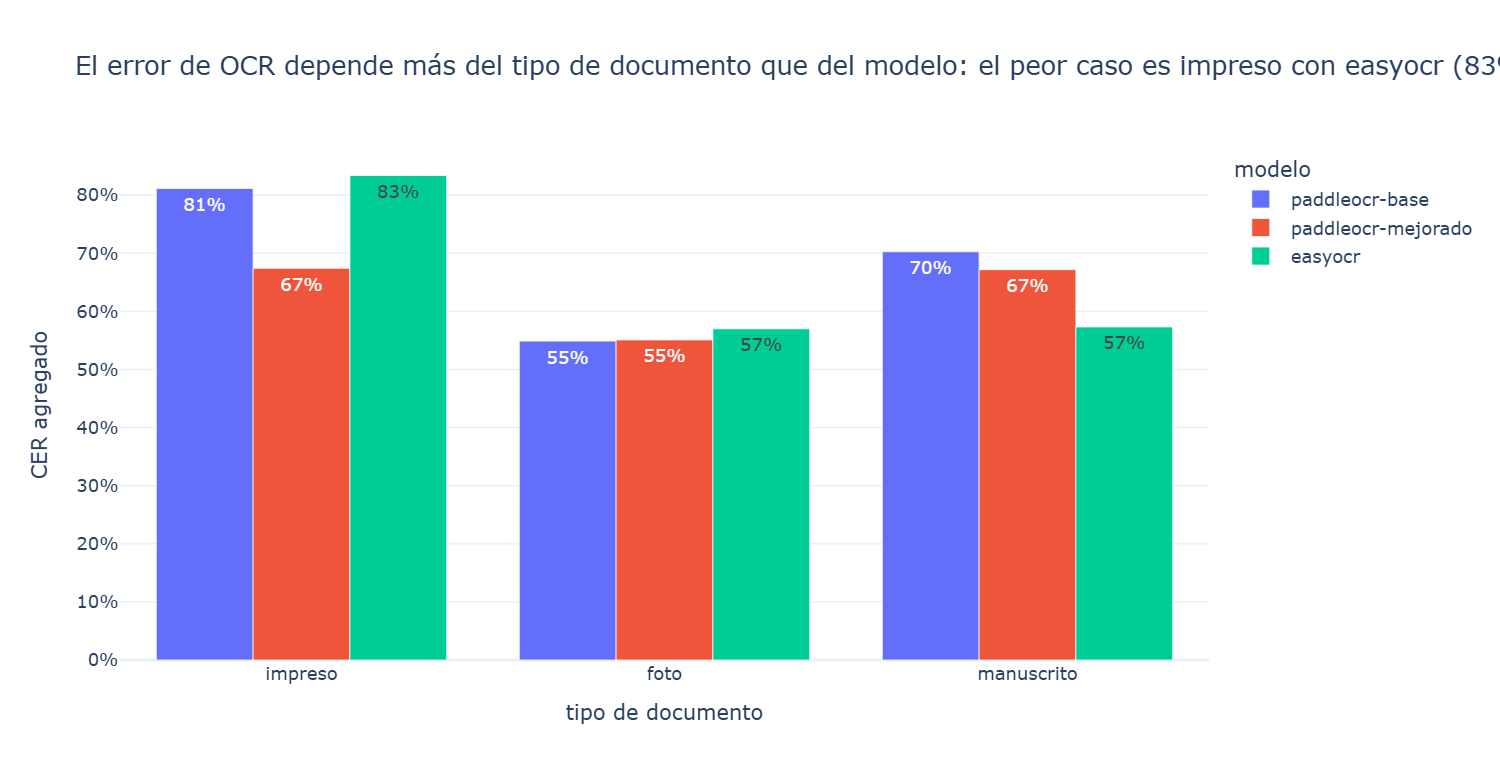

In [15]:
por_tipo = eval_ocr.groupby(["modelo", "tipo"], sort=False).apply(
    lambda g: t2.cer_corpus(eval_docs.set_index("id").loc[g["id"], "texto_referencia"], g["texto_hipotesis"])).rename("CER").reset_index()
peor = por_tipo.loc[por_tipo["CER"].idxmax()]
fig = px.bar(por_tipo, x="tipo", y="CER", color="modelo", barmode="group", text_auto=".0%",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
             labels={"CER": "CER agregado", "tipo": "tipo de documento"},
             title=f"El error de OCR depende más del tipo de documento que del modelo: el peor caso es "
                   f"{peor['tipo']} con {peor['modelo']} ({peor['CER']:.0%})")
fig.update_yaxes(tickformat=".0%")
t2.mostrar(fig, "04_cer_por_tipo")

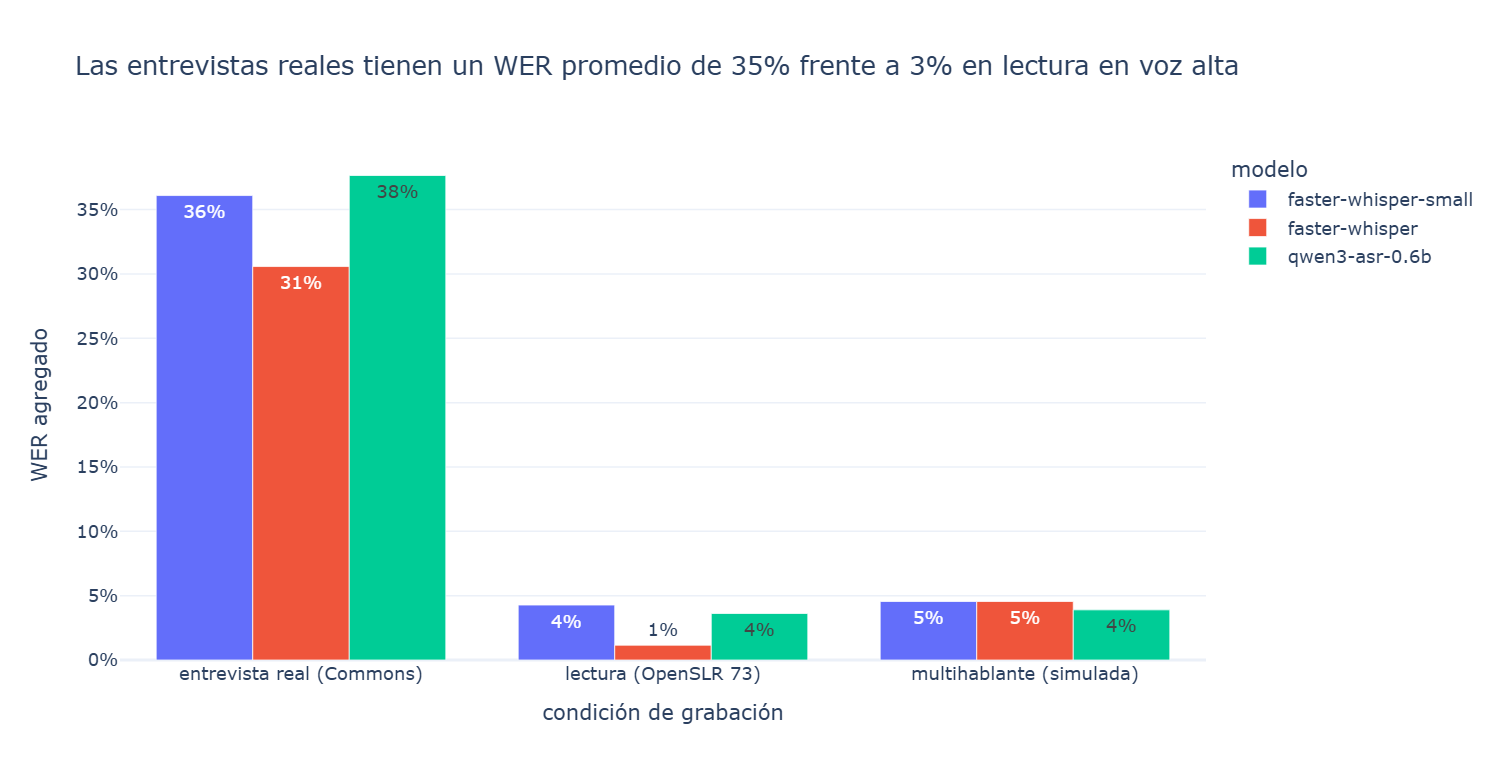

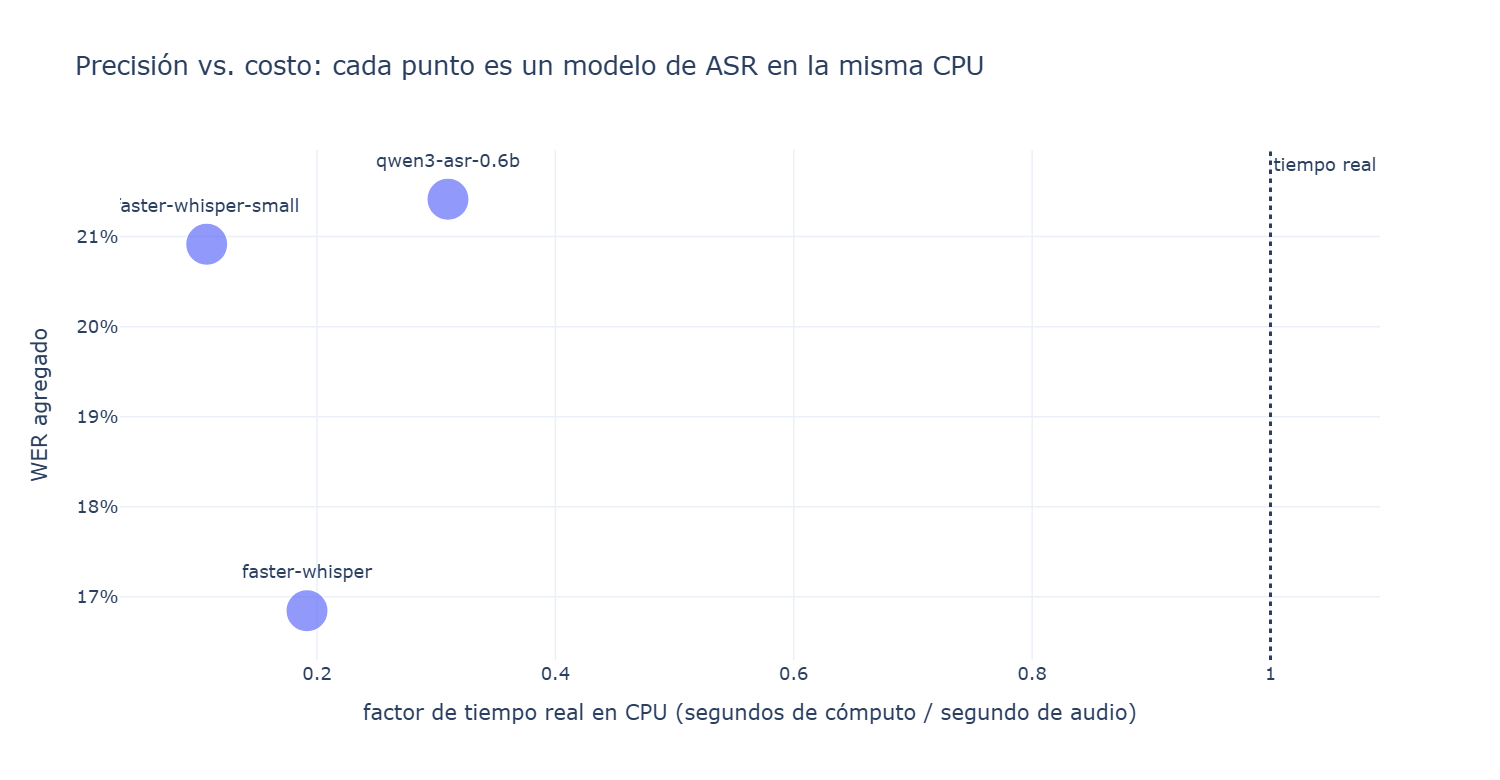

In [16]:
por_cond = eval_asr.groupby(["modelo", "condicion"], sort=False).apply(
    lambda g: t2.wer_corpus(eval_aud.set_index("id").loc[g["id"], "texto_referencia"], g["texto_hipotesis"])).rename("WER").reset_index()
lect = por_cond[por_cond["condicion"] == "lectura (OpenSLR 73)"]["WER"].mean()
real = por_cond[por_cond["condicion"] == "entrevista real (Commons)"]["WER"].mean()
fig = px.bar(por_cond, x="condicion", y="WER", color="modelo", barmode="group", text_auto=".0%",
             labels={"WER": "WER agregado", "condicion": "condición de grabación"},
             title=f"Las entrevistas reales tienen un WER promedio de {real:.0%} frente a {lect:.0%} en lectura en voz alta")
fig.update_yaxes(tickformat=".0%")
t2.mostrar(fig, "05_wer_por_condicion")

m_aud = metricas[metricas["modalidad"] == "audio"]
fig = px.scatter(m_aud, x="rtf", y="valor", text="modelo", size=[18] * len(m_aud),
                 labels={"rtf": "factor de tiempo real en CPU (segundos de cómputo / segundo de audio)", "valor": "WER agregado"},
                 title="Precisión vs. costo: cada punto es un modelo de ASR en la misma CPU")
fig.update_traces(textposition="top center")
fig.update_yaxes(tickformat=".0%")
fig.add_vline(x=1, line_dash="dot", annotation_text="tiempo real")
t2.mostrar(fig, "06_wer_vs_rtf")

## 8 · Casos difíciles

### 8.1 · Manuscritos y fotos

Para cada documento de la muestra: CER de cada modelo, y para el peor documento, un fragmento de la
referencia frente a lo que leyó la línea base.

In [17]:
cer_doc = eval_ocr.pivot_table(index=["id", "tipo"], columns="modelo", values="cer").round(3)
display(cer_doc.sort_index(level="tipo"))
peor_id = eval_ocr[eval_ocr["modelo"] == "paddleocr-base"].sort_values("cer").iloc[-1]["id"]
r = eval_docs.set_index("id").loc[peor_id]
hip = eval_ocr[(eval_ocr["id"] == peor_id) & (eval_ocr["modelo"] == "paddleocr-base")]["texto_hipotesis"].iloc[0]
print(f"Peor documento para la línea base: {peor_id} ({r.tipo}, {r.titulo})")
print("REFERENCIA :", " ".join(r.texto_referencia.split())[:400])
print("PADDLE BASE:", " ".join(hip.split())[:400])

,modelo,easyocr,paddleocr-base,paddleocr-mejorado
id,tipo,,,
doc_012,foto,0.738,0.788,0.628
doc_017,foto,0.188,0.113,0.151
doc_019,foto,0.325,0.076,0.707
doc_003,impreso,0.851,0.851,0.757
doc_005,impreso,0.836,0.808,0.589
doc_006,impreso,0.731,0.692,0.641
doc_007,impreso,0.909,0.886,0.705
doc_014,manuscrito,0.348,0.519,0.409
doc_026,manuscrito,1.279,1.841,2.024


Peor documento para la línea base: doc_026 (manuscrito, Asiento de la partida de bautismo de Raúl Porras Barrenechea.jpg)
REFERENCIA : N.º 21/11 En esta santa iglesia parroquiana de don Clemente de Pisco de la República del Perú. El suscrito certifica la autenticidad de la firma de la presente fotostática de Santiago. Pisco, 31 de enero de 1992.
PADDLE BASE: NUH Eneto Sante Yota Pamguat o San blemoente d Poe cajute lo Prum e Chineha d la Republea dlPoni, Juan nle cuad Slomtred md rchentes nrentaute a/ cun propu loutiortmmenk a pan Rat fhemacica Porvas. slvoon'ts's treca monso steest coe Lujs lpotirmo olel Sonve Gillrna Perasede lu n Suane Baneasa poras, pac S. melon sel DrE mlaepoine a Ngnx Cds Poras, asproentdeda pa l Dito Ginre Sueshsa De l euas iyf


### 8.2 · Audio con ruido de calle, voces superpuestas y varias personas

Comparamos palabra por palabra la referencia y la hipótesis de la línea base en el clip real con
más error (las palabras entre `[-…-]` faltan en la hipótesis y las `{+…+}` sobran), y revisamos si
algún modelo «alucinó» frases típicas de Whisper.

In [18]:
base_asr = eval_asr[eval_asr["rol"] == "base"]
peor = base_asr.sort_values("wer").iloc[-1]
ref = t2.normalizar(eval_aud.set_index("id").loc[peor["id"], "texto_referencia"]).split()
hipo = t2.normalizar(peor["texto_hipotesis"]).split()
salida = []
for op, a1, a2, b1, b2 in difflib.SequenceMatcher(a=ref, b=hipo, autojunk=False).get_opcodes():
    if op == "equal":
        salida.append(" ".join(ref[a1:a2]))
    if op in ("delete", "replace"):
        salida.append("[-" + " ".join(ref[a1:a2]) + "-]")
    if op in ("insert", "replace"):
        salida.append("{+" + " ".join(hipo[b1:b2]) + "+}")
print(f"{peor['id']} ({peor['condicion']}) · WER {peor['wer']:.0%}\n")
print(" ".join(salida)[:1500])

alu = eval_asr[eval_asr["alucinaciones"] != ""]
print(f"\nSalidas con posibles alucinaciones: {len(alu)}")
if len(alu):
    display(alu[["id", "modelo", "condicion", "alucinaciones"]])
sim = aud[aud["condicion"] == "multihablante (simulada)"]
print("\nDiarización (Parte 1): la entrevista simulada de 2 hablantes quedó con", sim["n_hablantes"].tolist(), "hablante(s) detectado(s)")

clip_010 (entrevista real (Commons)) · WER 90%

[-cómo se llama usted persona 8-] {+chuyas verdad+} usted pertenece [-al pueblo de chuyas chuyas verdad sí es chuyas usted pertenece al pueblo sí-] {+a pablo+} sí y cómo está viviendo [-este-] {+ese+} momento [-bien recordando-] pues [-en-] sí la imagen se celebra ya en la sierra en chuyas pero acá ya bueno [-para no perder el costumbre no es lo mismo celebrarlo en chuyas que aquí no es lo mismo pero sí ahí vamos bueno porque con gusto con feliz estamos celebrando aquí usted suele venir siempre a estas fiestas o sí siempre siempre siempre siempre y cómo nota la población hay bastante o muy poca gente no lo veo mucho antes había mucho más gente hoy está poquito creo que va a estar todavía así ha disminuido poco a poco probablemente y las presentaciones que se dan siempre son similares sí sí y me podría explicar qué significan algunas de ellas mira la baile de la primera se llama yunca es un costumbre es un costumbre de imagen y de qué va e

,id,modelo,condicion,alucinaciones
12,clip_012,faster-whisper,entrevista real (Commons),repetición: ya está grabando



Diarización (Parte 1): la entrevista simulada de 2 hablantes quedó con [2] hablante(s) detectado(s)


### 8.3 · Bonificación (opcional): quechua de Huaylas con MMS

Se activa poniendo `"bonus_mms_quechua": true` en la configuración (MMS-1b-all pesa ~4 GB). Para
reportar WER hace falta una transcripción manual en quechua en `datos/raw/referencias/quechua.txt`
hecha o validada por una persona que hable la variedad.

In [19]:
if CFG.get("bonus_mms_quechua"):
    inv = pd.read_csv(RAW / "audio" / "inventario.csv", keep_default_na=False)
    fila = inv[inv["idioma"] == "qwh"].iloc[0]
    xq = voz.cargar_audio(RAIZ / fila["archivo"])[:30 * voz.SR]
    mms = voz.Transcriptor("mms", idioma_mms="qwh")
    hip_q = mms.transcribir(xq)
    print("MMS [qwh]:", hip_q)
    ref_q = RAW / "referencias" / "quechua.txt"
    if ref_q.exists():
        print(f"WER quechua: {t2.wer_uno(ref_q.read_text(encoding='utf-8'), hip_q):.2f}")
else:
    print("Bonificación MMS desactivada en la configuración")

Bonificación MMS desactivada en la configuración


## 9 · Resultado de la auditoría humana

In [20]:
aud_h = pd.read_excel(plantilla, dtype={"error_observado": str}).fillna({"error_observado": ""})
cols_ok = ["ok_modalidad_tema_resumen", "ok_campos_con_valor", "ok_nulls"]
aud_h["completamente_correcta"] = (aud_h[cols_ok].astype(int).sum(axis=1) == 3).astype(int)
correctas = int(aud_h["completamente_correcta"].sum())
print(f"Acuerdo LLM-Humano: {correctas}/20 = {correctas / 20:.0%} de extracciones completamente correctas")
display(aud_h.groupby("modalidad")["completamente_correcta"].agg(["sum", "count"]))
print("\nEjemplos de errores:")
display(aud_h[aud_h["completamente_correcta"] == 0][["id", "modalidad", "error_observado"]])
aud_h.drop(columns=["texto_fuente"]).to_csv(DATOS / "auditoria_llm.csv", index=False, encoding="utf-8")

Acuerdo LLM-Humano: 17/20 = 85% de extracciones completamente correctas


,sum,count
modalidad,,
audio,9,10
documento,8,10



Ejemplos de errores:


,id,modalidad,error_observado
7,doc_002,documento,el emisor sí estaba (MERCURIO PERUANO) y quedó null
9,doc_015,documento,"el resumen dice ""julio"", pero el texto solo dice ""Jeileo"""
13,clip_027,audio,el resumen inventa viajes a Argentina y Veracruz; solo se pregunta qué pasa allí


## 10 · Decisión y resultados finales sobre la muestra de evaluación

Se aplica la regla definida de antemano en la configuración:

In [21]:
print("Regla:", CFG["regla_de_decision"], "\n")

def elegir(m, limite_col, limite):
    ok = m[m[limite_col] <= limite] if m[limite_col].notna().any() else m
    ok = ok if len(ok) else m
    mejor = ok["valor"].min()
    empatados = ok[ok["valor"] <= mejor + 0.01]
    return empatados.sort_values(limite_col).iloc[0]

el_ocr = elegir(metricas[metricas["modalidad"] == "documentos"], "segundos_por_item", 30)
el_asr = elegir(metricas[metricas["modalidad"] == "audio"], "rtf", 1.0)
base_ocr = metricas[(metricas["modalidad"] == "documentos") & (metricas["rol"] == "base")].iloc[0]
base_asr_m = metricas[(metricas["modalidad"] == "audio") & (metricas["rol"] == "base")].iloc[0]
print(f"OCR elegido: {el_ocr['modelo']} · CER {el_ocr['valor']:.3f} (línea base {base_ocr['valor']:.3f}) · {el_ocr['segundos_por_item']:.1f} s/página")
print(f"ASR elegido: {el_asr['modelo']} · WER {el_asr['valor']:.3f} (línea base {base_asr_m['valor']:.3f}) · RTF {el_asr['rtf']:.2f}")

resumen = {"modelo_ocr_elegido": el_ocr["modelo"], "cer": round(float(el_ocr["valor"]), 4),
           "cer_base": round(float(base_ocr["valor"]), 4), "modelo_asr_elegido": el_asr["modelo"],
           "wer": round(float(el_asr["valor"]), 4), "wer_base": round(float(base_asr_m["valor"]), 4),
           "rtf_asr": round(float(el_asr["rtf"]), 3), "acuerdo_llm_humano": f"{correctas}/20",
           "pct_acuerdo": correctas / 20, "modelo_llm": ext.modelo, "fecha": time.strftime("%Y-%m-%d")}
(DATOS / "resumen_resultados.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"\nResultados Test: WER: {el_asr['valor']:.2f} | CER: {el_ocr['valor']:.2f} | Acuerdo LLM-Humano: {correctas}/20")

Regla: Se elige, por modalidad, el modelo con menor CER/WER agregado cuyo factor de tiempo real en CPU sea <= 1.0 (ASR) o que tarde <= 30 s por página (OCR). Empates (<1 punto porcentual): el más liviano. 

OCR elegido: easyocr · CER 0.606 (línea base 0.653) · 6.5 s/página
ASR elegido: faster-whisper · WER 0.168 (línea base 0.209) · RTF 0.19

Resultados Test: WER: 0.17 | CER: 0.61 | Acuerdo LLM-Humano: 17/20


### Justificación y reflexión

**Resultados sobre la muestra (10 documentos y 10 clips, referencias manuales):**

| Modalidad | Modelo | Error agregado | Costo en CPU |
|---|---|---|---|
| OCR | PaddleOCR base (línea base) | CER 65,3 % | 39,8 s/página |
| OCR | PaddleOCR mejorado (orientación + unwarping) | CER 62,2 % | 32,4 s/página |
| OCR | **EasyOCR** | **CER 60,6 %** | **6,5 s/página** |
| ASR | faster-whisper small (línea base) | WER 20,9 % | RTF 0,11 |
| ASR | **faster-whisper large-v3-turbo** | **WER 16,8 %** | RTF 0,19 |
| ASR | Qwen3-ASR 0.6B | WER 21,4 % | RTF 0,31 |

**Elección para un entorno real (precisión, costo, latencia).**
- **ASR: faster-whisper large-v3-turbo.** Baja el WER de 20,9 % a 16,8 % y sigue siendo 5 veces más rápido que el tiempo real en una laptop sin GPU (RTF 0,19): una hora de entrevistas se transcribe en ~12 minutos. Qwen3-ASR no mejoró a la línea base en español peruano y fue el más lento en CPU.
- **OCR: depende del documento, no hay un ganador universal.** Por la regla fijada de antemano gana EasyOCR (menor CER agregado y 6 veces más rápido), pero la diferencia de CER entre los tres (61–65 %) es pequeña frente a la diferencia entre tipos de documento. Para fotos de placas en la calle, PaddleOCR base fue claramente el mejor (CER 8 % y 11 % en doc_019 y doc_017, frente a 32 % y 19 % de EasyOCR). En producción usaría EasyOCR como primer filtro barato y PaddleOCR base para fotos de escena.

**Por tipo de documento.**
- **Impresos (billetes de intis): CER 59–91 %, peor de lo esperado, y la causa es la referencia, no la lectura.** El OCR lee bien el texto principal ("BANCO CENTRAL DE RESERVA DEL PERU", "28 DE JUNIO DE 1988", el número de serie), pero también lee todo lo demás que trae el billete: la serie repetida, "DIRECTOR", "PRESIDENTE", "GERENTE GENERAL" y restos del fondo ornamental. La referencia manual transcribió solo el texto principal (73 caracteres frente a 124 leídos en doc_005), así que todo lo extra cuenta como inserciones. Además, el OCR pega palabras ("DERESERVADELPERU", "MILINTS"), como ya se vio en la Sesión 10. Lección: el CER depende tanto de la regla de transcripción como del modelo.
- **Fotos con sombra o inclinación: el mejor caso (CER 8–19 % en placas)**, salvo el cartel chicha doc_012 (CER 63–79 %), con muchas tipografías decorativas y varios bloques de texto. El preprocesamiento de PaddleOCR "mejorado" ayudó en doc_012, pero empeoró la placa doc_019 (CER de 8 % a 71 %): el unwarping deformó una foto que ya estaba plana.
- **Manuscritos: el peor caso y el más variable.** La partida de bautismo doc_026 tuvo CER > 100 %: el OCR produjo 547 caracteres de basura ("NUH Eneto Sante Yota…") contra 208 de la referencia. En cambio, el título caligráfico del libro de Lampa (doc_031) tuvo 20 %. La confianza mediana del OCR en manuscritos (0,77) fue claramente menor que en impresos (1,00) y fotos (0,99): la confianza sirve como alarma para mandar a revisión humana.

**Por tipo de audio.**
- **Lectura limpia (OpenSLR 73): WER 0–4 %** con turbo. Es casi perfecto: un solo hablante, micrófono cercano y sin ruido.
- **Entrevistas reales: WER entre 4 % y 90 %.** En tres de las cuatro (clip_008, 012 y 015) el WER fue 4–8 % con turbo; el modelo grande ayudó sobre todo en la marcha con ruido (clip_012: 23 % → 8 %). El caso extremo es **clip_010 (WER 86–93 % en los tres modelos)**: los modelos devolvieron ~40 palabras donde la persona transcribió 265. La entrevistada habla bajo y lejos del micrófono, y el VAD descartó gran parte de su voz como si fuera silencio. No es una alucinación: es una **omisión**, y por eso no la detecta ninguna alarma automática.
- **Varias voces:** en la entrevista simulada (2 hablantes) el WER fue 4–5 % y la diarización encontró correctamente 2 hablantes. En la marcha (clip_012) la diarización sobresegmentó a 11 "hablantes": el ruido de fondo y los gritos generan huellas de voz distintas.

**LLM (Gemini): 17/20 extracciones completamente correctas (85 %).** Los tres errores son de tipos distintos:
1. **Omisión** (doc_002): el emisor "Mercurio Peruano" estaba en el texto y quedó en null.
2. **"Corrección" no pedida** (doc_015): el OCR leyó "Jeileo" y el LLM escribió "julio" en el resumen. Es un buen reflejo del idioma, pero no es lo que dice el texto.
3. **Alucinación** (clip_027): el resumen inventa viajes a Argentina y Veracruz que nadie hizo; en el audio solo se pregunta qué pasa allí.

El chequeo automático de citas literales (28/30 audios) no detecta estos errores: la auditoría humana sigue siendo necesaria. Durante la extracción el modelo gemini-3.8-flash agotó su cuota gratuita y el código pasó automáticamente a gemini-3.6-flash y gemini-3.5-flash-lite (columna `modelo_llm`).

**Limitación metodológica.** Las métricas salen de solo 10 + 10 archivos: un solo documento (doc_026) o un solo clip (clip_010) mueve el error agregado varios puntos. Tesseract no se evaluó porque no estaba instalado en el equipo.
